# Transverse shear stresses through the thickness

The FSDT gives constant transverse shear strains through the thickness. The
stresses that satisfy equilibrium, vanish at the faces and are continuous at
the ply interfaces are given by `calc_transverse_shear_stress`, for given
shear forces, and by `calc_equilibrium_transverse_shear`, from the strain
gradients of an actual solution. This tutorial also compares the shear
correction methods. SI units are used throughout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate, isotropic_plate

laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
plyt = 0.25e-3

## Stresses for given shear forces

For a cross-ply $[0/90]_s$ laminate and a homogeneous plate of the same
thickness, the stresses of the shear force $Q_x$ are compared with the
parabola $\tau_{xz} = 3 Q_x/(2h) (1 - 4z^2/h^2)$. The arguments are
`(z, Qy, Qx)` and the results `(tau_yz, tau_xz)`.

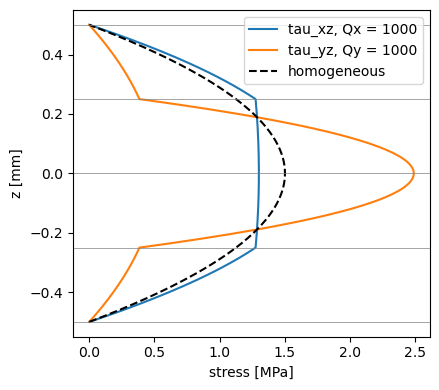

In [2]:
cp = laminated_plate([0, 90, 90, 0], plyt=plyt, laminaprop=laminaprop)
h = cp.h
Qx = 1e3 # N/m
zs = np.linspace(-h/2, h/2, 201)
tau_xz = [cp.calc_transverse_shear_stress(z, 0., Qx)[1] for z in zs]
tau_yz = [cp.calc_transverse_shear_stress(z, Qx, 0.)[0] for z in zs]
parabola = 3*Qx/(2*h)*(1 - 4*zs**2/h**2)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(np.array(tau_xz)/1e6, zs*1e3, label='tau_xz, Qx = %g' % Qx)
ax.plot(np.array(tau_yz)/1e6, zs*1e3, label='tau_yz, Qy = %g' % Qx)
ax.plot(parabola/1e6, zs*1e3, 'k--', label='homogeneous')
for zi in np.linspace(-h/2, h/2, 5):
    ax.axhline(zi*1e3, color='gray', lw=0.5)
ax.set_xlabel('stress [MPa]')
ax.set_ylabel('z [mm]')
ax.legend()
fig.tight_layout()

The stresses vanish at the faces and change slope at the interfaces. The
shear correction of `'rohwer'` is the ratio between the strain energy of
these stresses and the one of constant strains:

In [3]:
print('scf_k13 = A55/Abar55 = %.4f' % cp.scf_k13)
print('scf_k23 = A44/Abar44 = %.4f' % cp.scf_k23)

scf_k13 = A55/Abar55 = 0.7454
scf_k23 = A44/Abar44 = 0.6685


## Angle-ply coupling

In a $[45/-45]_s$ laminate, a shear force $Q_x$ also creates $\tau_{yz}$,
through the bending-twisting coupling $D_{16}$, $D_{26}$. The coupling term
`A45` of `Ats` is not zero, although `Abar45` is.

Ats =
 [[3136030.33223062  122955.17981668]
 [ 122955.17981668 3136030.33223062]]
Abar_ts =
 [[4150000.       0.]
 [      0. 4150000.]]


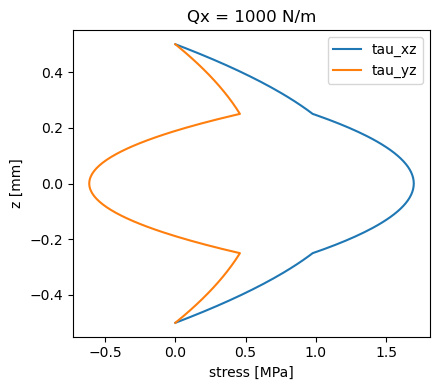

In [4]:
ap = laminated_plate([45, -45, -45, 45], plyt=plyt, laminaprop=laminaprop)
tau = np.array([ap.calc_transverse_shear_stress(z, 0., Qx) for z in zs])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(tau[:, 1]/1e6, zs*1e3, label='tau_xz')
ax.plot(tau[:, 0]/1e6, zs*1e3, label='tau_yz')
ax.set_xlabel('stress [MPa]')
ax.set_ylabel('z [mm]')
ax.set_title('Qx = %g N/m' % Qx)
ax.legend()
fig.tight_layout()
print('Ats =\n', ap.Ats)
print('Abar_ts =\n', ap.Abar_ts)

## Stresses recovered from strain gradients

`calc_equilibrium_transverse_shear` integrates the equilibrium equations
from the bottom face with the derivatives of the generalized strains
$\{\varepsilon^{(0)}, \varepsilon^{(1)}\}$, e.g. of an FSDT solution. In
cylindrical bending about $y$, with $M_{xx,x} = Q_x$ and the other
derivatives of the resultants equal to zero, the strain gradients are
`inv(ABD) @ {0, 0, 0, Qx, 0, 0}`, and the recovered stresses coincide with
those of `calc_transverse_shear_stress`.

In [5]:
eps_x = np.linalg.solve(cp.ABD, [0, 0, 0, Qx, 0, 0])
eps_y = np.zeros(6)
z, tyz, txz = cp.calc_equilibrium_transverse_shear(eps_x, eps_y, z=zs)
print('max difference [Pa]:',
      np.abs(txz[0] - np.array(tau_xz)).max())

max difference [Pa]: 6.984919309616089e-10


`calc_aposteriori_energy` gives the transverse shear strain energies of the
recovered stresses, from which the a posteriori factor of Noor and Peters,
$k_{13} = Q_x^2 / (2 \bar{A}_{55} U_{13})$, follows:

In [6]:
U13, U23, Qy_r, Qx_r = cp.calc_aposteriori_energy(eps_x, eps_y)
print('resultant of the recovered stresses: Qx = %.6f N/m' % Qx_r[0])
print('a posteriori k13 = %.4f' % (Qx**2/(2*cp.Abar55*U13[0])))
print("'rohwer' scf_k13 = %.4f" % cp.scf_k13)

resultant of the recovered stresses: Qx = 1000.000000 N/m
a posteriori k13 = 0.7454
'rohwer' scf_k13 = 0.7454


## Comparison of the shear correction methods

The methods are selected with the argument `shear_correction`. For a
homogeneous plate most of them give 5/6; they differ for laminates, in
particular for a sandwich with a soft core. `'thickness_shear'` requires the
densities of the plies.

In [7]:
core = (0.1e9, 0.1e9, 0.3, 0.04e9, 0.04e9, 0.04e9)
laminates = {
    'isotropic': dict(stack=[0], plyt=1e-3, laminaprop=(70e9, 0.3),
                      rho=2700.),
    '[0/90]s': dict(stack=[0, 90, 90, 0], plyt=plyt, laminaprop=laminaprop,
                    rho=1600.),
    'sandwich': dict(stack=[0, 90, 0, 90, 0], plyts=[plyt, plyt, 10e-3,
                     plyt, plyt],
                     laminaprops=[laminaprop, laminaprop, core, laminaprop,
                                  laminaprop],
                     rhos=[1600., 1600., 50., 1600., 1600.]),
}
methods = ['rohwer', 'vlachoutsis', 'birman_bert', 'thickness_shear',
           'constant']
print('%-12s' % 'k13' + ''.join('%17s' % m for m in methods))
for name, kwargs in laminates.items():
    k13 = [laminated_plate(shear_correction=m, **kwargs).scf_k13
           for m in methods]
    print('%-12s' % name + ''.join('%17.4f' % k for k in k13))

k13                    rohwer      vlachoutsis      birman_bert  thickness_shear         constant
isotropic              0.8333           0.8333           1.0000           0.8225           0.8333
[0/90]s                0.7454           0.7453           0.8882           0.6788           0.8333
sandwich               0.1010           0.1010           0.1036           0.0959           0.8333
